# IBAMA licensing records

**Output:** `datasets/ibama/final.gpkg` (a byte-for-byte verified local copy of the preserved baseline). The `licensed_projects_st` layer holds point, line and polygon records and an English sector label.

**Why:** A licensed record identifies an administrative activity, not a completed project or measured environmental impact. The notebook reruns the [active IBAMA translation](../../code/brazil_project/infrastructure/projects.py) from the configured local snapshot, compares every preserved field and geometry with the baseline, and copies that baseline only if they agree. [Original processing report](../../research/reports/ibama_data_extraction.md).

In [1]:
DATASET = "ibama"
from pathlib import Path
import os, sys, sqlite3
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "project.toml").is_file())
sys.path[:0] = [str(PROJECT / "code"), str(PROJECT / "datasets"), str(PROJECT / "datasets" / DATASET)]
from processing import build, inspect_final
REBUILD = os.environ.get("BRAZIL_NOTEBOOK_REBUILD", "1") == "1"
print("Project:", PROJECT.name)
print("Mode:", "build from local inputs" if REBUILD else "preview existing verified local output")

Project: brazil-project
Mode: preview existing verified local output


## 1. Translate and verify the saved snapshot

The active stage translates the original Portuguese sector codes and writes local intermediate data. Acquisition is never automatic. The handoff checks record order, attributes, CRS and geometry against the inventoried GeoPackage before making a final copy.

In [2]:
result = build(PROJECT) if REBUILD else inspect_final(PROJECT, preview=True)
display(pd.DataFrame([{"licensed source records": result["features"],
                       "CRS": f"EPSG:{result['epsg']}"}]))
print("Local GeoPackage:", Path(result["file"]).relative_to(PROJECT))
print("SHA-256:", result["sha256"])

,licensed source records,CRS
0,8494,EPSG:4674


Local GeoPackage: outputs/maps/notebook-exports/ibama.gpkg
SHA-256: 0df410feb5e5aaa975851107fc501c408d2ed7ceb15a72e21a573462e0773863


## 2. Inspect sector coverage

Counts below are **source records**, not distinct developments.

,sector,source_records
0,Transportation,5233
1,Energy,2013
2,Other,512
3,Mining,420
4,Oil and Gas,219
5,Water Resources,72
6,Nuclear/Radioactive,25


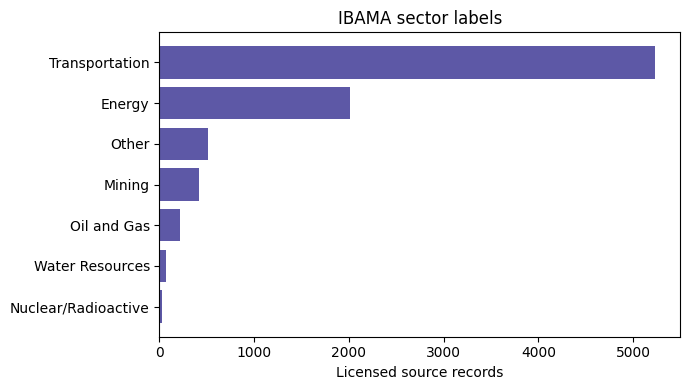

In [3]:
with sqlite3.connect(f"file:{result['file']}?mode=ro", uri=True) as db:
    sectors = pd.read_sql_query('SELECT COALESCE(tp_sector_en, "Untranslated") AS sector, COUNT(*) AS source_records FROM licensed_projects_st GROUP BY tp_sector_en ORDER BY source_records DESC', db)
display(sectors)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(sectors.sector.iloc[::-1], sectors.source_records.iloc[::-1], color="#5d58a6")
ax.set_xlabel("Licensed source records")
ax.set_title("IBAMA sector labels")
fig.tight_layout()
display(fig)
plt.close(fig)

## 3. Check which IDs reached the frozen website tiles

The highest-zoom archive can repeat one source feature across several tiles, so compare **distinct source IDs**. This is an optional read-only check when the saved website archive is available locally; it does not establish equality of geometry or attributes.

In [4]:
from processing import website_id_check
website_ids = website_id_check(PROJECT)
display(pd.DataFrame([{
    "source IDs": website_ids.get("source_ids"),
    "website IDs": website_ids.get("website_ids"),
    "source IDs absent from tiles": len(website_ids.get("source_ids_absent_from_tiles", [])),
    "tile IDs absent from source": len(website_ids.get("website_ids_absent_from_source", [])),
}]))
print("Comparison:", website_ids)

,source IDs,website IDs,source IDs absent from tiles,tile IDs absent from source
0,8494,8492,2,0


Comparison: {'status': 'identifier comparison only', 'source_ids': 8494, 'website_ids': 8492, 'source_ids_absent_from_tiles': [136441, 3347413], 'website_ids_absent_from_source': []}


**Limit:** In the locally saved website archive, two of 8,494 source IDs are absent from the highest-zoom tiles: `136441` and `3347413`. Both remain in this original GeoPackage. Tiling can omit geometry for display; the reason for these two omissions has not been independently established. Attribute and geometry parity with the website tiles remains unverified.